In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
df = pd.read_csv("/content/Wholesale customers data.csv")
df.head()
print(df.tail())
print(df.shape)
df.info()
print(df.describe())


     Channel  Region  Fresh   Milk  Grocery  Frozen  Detergents_Paper  \
435        1       3  29703  12051    16027   13135               182   
436        1       3  39228   1431      764    4510                93   
437        2       3  14531  15488    30243     437             14841   
438        1       3  10290   1981     2232    1038               168   
439        1       3   2787   1698     2510      65               477   

     Delicassen  
435        2204  
436        2346  
437        1867  
438        2125  
439          52  
(440, 8)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 440 entries, 0 to 439
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   Channel           440 non-null    int64
 1   Region            440 non-null    int64
 2   Fresh             440 non-null    int64
 3   Milk              440 non-null    int64
 4   Grocery           440 non-null    int64
 5   Frozen            44

In [ ]:
# Question 1: How many customers belong to each channel and region?
print( df["Channel"].value_counts())
print(df["Region"].value_counts())

Channel
1    298
2    142
Name: count, dtype: int64
Region
3    316
1     77
2     47
Name: count, dtype: int64


In [ ]:
# Question 2: Which product category has the highest total and average spending?
categories=['Fresh','Milk','Grocery','Frozen','Detergents_Paper','Delicassen']
total_spending = df[categories].sum()
average_spending = df[categories].mean()
print(total_spending.sort_values(ascending=False))
print(' ')
print(average_spending.sort_values(ascending=False))
print(' ')
print("Category with highest total:", total_spending.idxmax())
print("Category with highest average:", average_spending.idxmax())

Fresh               5280131
Grocery             3498562
Milk                2550357
Frozen              1351650
Detergents_Paper    1267857
Delicassen           670943
dtype: int64
 
Fresh               12000.297727
Grocery              7951.277273
Milk                 5796.265909
Frozen               3071.931818
Detergents_Paper     2881.493182
Delicassen           1524.870455
dtype: float64
 
Category with highest total: Fresh
Category with highest average: Fresh


In [ ]:
# Question 3: Calculate mean, median, minimum and maximum spending for each category (using NumPy).
data_array = df[categories].values
for i in range(len(categories)):
    column = data_array[:, i]
    print(categories[i])
    print("  Mean   :", np.mean(column))
    print("  Median :", np.median(column))
    print("  Min    :", np.min(column))
    print("  Max    :", np.max(column))
    print(" ")

Fresh
  Mean   : 12000.297727272728
  Median : 8504.0
  Min    : 3
  Max    : 112151
 
Milk
  Mean   : 5796.265909090909
  Median : 3627.0
  Min    : 55
  Max    : 73498
 
Grocery
  Mean   : 7951.277272727273
  Median : 4755.5
  Min    : 3
  Max    : 92780
 
Frozen
  Mean   : 3071.931818181818
  Median : 1526.0
  Min    : 25
  Max    : 60869
 
Detergents_Paper
  Mean   : 2881.4931818181817
  Median : 816.5
  Min    : 3
  Max    : 40827
 
Delicassen
  Mean   : 1524.8704545454545
  Median : 965.5
  Min    : 3
  Max    : 47943
 


In [ ]:
# Question 4: Find the 10 customers with the highest total spending across categories.
df["Total_Spending"] = np.sum(data_array, axis=1)
top10 = df.sort_values("Total_Spending", ascending=False).head(10)
print(top10[["Channel", "Region", "Total_Spending"]])

     Channel  Region  Total_Spending
85         2       3          199891
47         2       3          192714
181        1       3          190169
183        1       3          185683
61         2       3          165881
86         2       3          150497
325        1       2          130877
333        2       2          120291
23         2       3          110829
211        2       1          107155


In [ ]:
# Question 5: Compare average category spending between the two channels.
channel_average = df.groupby("Channel")[categories].mean()
print(channel_average)

                Fresh          Milk       Grocery       Frozen  \
Channel                                                          
1        13475.560403   3451.724832   3962.137584  3748.251678   
2         8904.323944  10716.500000  16322.852113  1652.612676   

         Detergents_Paper   Delicassen  
Channel                                 
1              790.560403  1415.956376  
2             7269.507042  1753.436620  


In [ ]:
# Question 6: Check missing values and duplicates.
print(df.isnull().sum())
print(df.duplicated().sum())


Channel             0
Region              0
Fresh               0
Milk                0
Grocery             0
Frozen              0
Detergents_Paper    0
Delicassen          0
Total_Spending      0
dtype: int64
0


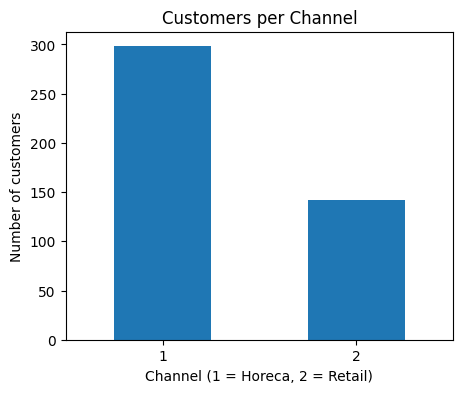

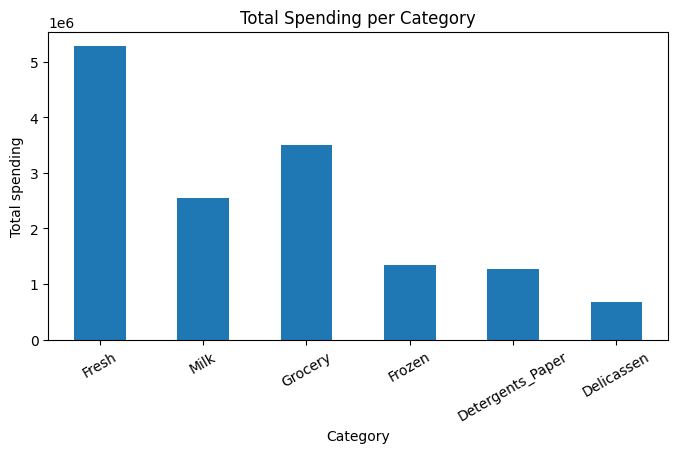

In [ ]:
# Make a channel-count bar chart and a category-spending bar chart.
import pandas as pd
df=pd.read_csv("/content/Wholesale customers data.csv")
channel_counts = df["Channel"].value_counts()
plt.figure(figsize=(5, 4))
channel_counts.plot(kind="bar")
plt.title("Customers per Channel")
plt.xlabel("Channel (1 = Horeca, 2 = Retail)")
plt.ylabel("Number of customers")
plt.xticks(rotation=0)
plt.show()

plt.figure(figsize=(8, 4))
total_spending.plot(kind="bar")
plt.title("Total Spending per Category")
plt.xlabel("Category")
plt.ylabel("Total spending")
plt.xticks(rotation=30)
plt.show()

In [ ]:
# Observations:
# 1. The category with the highest total spending is Fresh
# 2. The channel with the most customers is 1 with 298 customers
# 3. Fresh mean is 12000.3 but median is 8504.0 - if the mean is bigger, a few big customers pull the average up